In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("lan_img1.jpg")

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

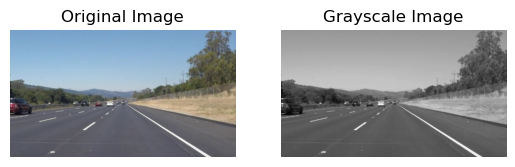

In [4]:
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

Threshold used: 189


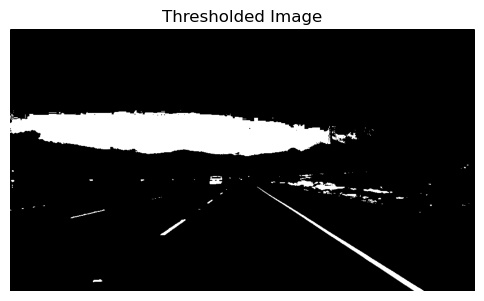

In [5]:
threshold = int(np.percentile(gray, 90))
print("Threshold used:", threshold)
_, thresh = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(6, 5))
plt.imshow(thresh, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

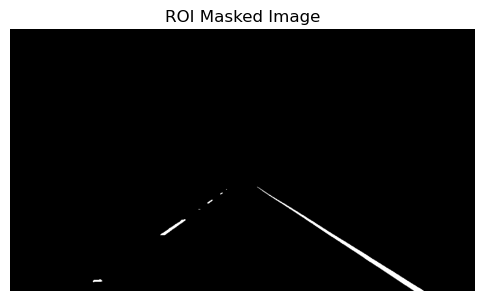

In [6]:
height, width = thresh.shape

# Trapezoid covering the road ahead
polygon = np.array([[
    (0, height),
    (width, height),
    (int(0.55 * width), int(0.6 * height)),
    (int(0.45 * width), int(0.6 * height))
]], dtype=np.int32)

mask = np.zeros_like(thresh)
cv2.fillPoly(mask, polygon, 255)
masked = cv2.bitwise_and(thresh, mask)

plt.figure(figsize=(6, 5))
plt.imshow(masked, cmap="gray")
plt.title("ROI Masked Image")
plt.axis("off")
plt.show()

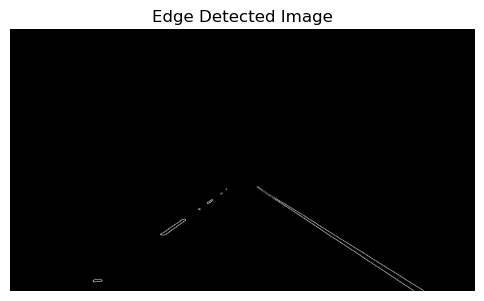

In [7]:
edges = cv2.Canny(masked, 50, 150)

plt.figure(figsize=(6, 5))
plt.imshow(edges, cmap="gray")
plt.title("Edge Detected Image")
plt.axis("off")
plt.show()

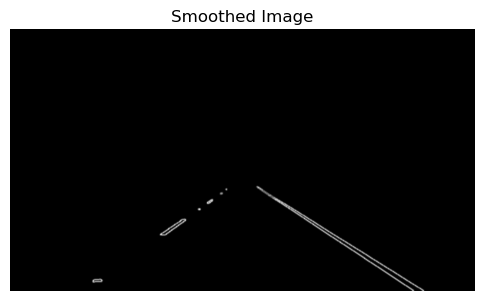

In [8]:
blur = cv2.GaussianBlur(edges, (5, 5), 0)

plt.figure(figsize=(6, 5))
plt.imshow(blur, cmap="gray")
plt.title("Smoothed Image")
plt.axis("off")
plt.show()

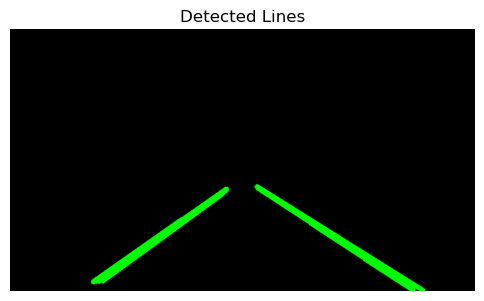

In [9]:
lines = cv2.HoughLinesP(blur, 1, np.pi / 180, threshold=50,
                        minLineLength=50, maxLineGap=150)

line_img = np.zeros_like(img)
if lines is not None:
    lines = lines.reshape(-1, 4)
    for x1, y1, x2, y2 in lines:
        cv2.line(line_img, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines")
plt.axis("off")
plt.show()

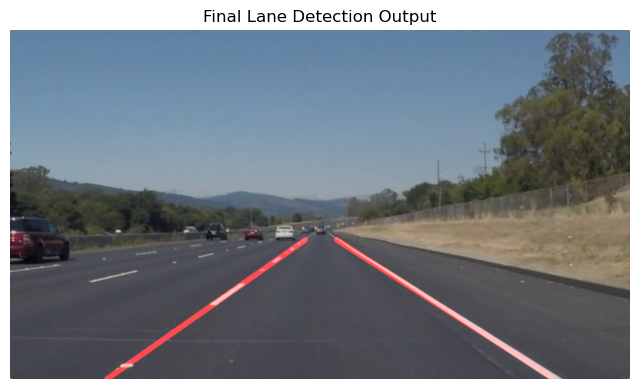

In [10]:
left_fit = []
right_fit = []

if lines is not None:
    for x1, y1, x2, y2 in lines.reshape(-1, 4):
        if x1 == x2:
            continue
        slope = (y2 - y1) / (x2 - x1)
        intercept = y1 - slope * x1
        # Image y-axis points down: left lane has negative slope, right lane positive
        if slope < -0.3:
            left_fit.append((slope, intercept))
        elif slope > 0.3:
            right_fit.append((slope, intercept))

def make_points(y_bottom, y_top, fit):
    slope, intercept = fit
    x_bottom = int((y_bottom - intercept) / slope)
    x_top = int((y_top - intercept) / slope)
    return (x_bottom, y_bottom, x_top, y_top)

h = img.shape[0]
y_bottom = h
y_top = int(h * 0.6)

lane_img = np.zeros_like(img)

if len(left_fit) > 0:
    x1, y1, x2, y2 = make_points(y_bottom, y_top, np.mean(left_fit, axis=0))
    cv2.line(lane_img, (x1, y1), (x2, y2), (0, 0, 255), 8)

if len(right_fit) > 0:
    x1, y1, x2, y2 = make_points(y_bottom, y_top, np.mean(right_fit, axis=0))
    cv2.line(lane_img, (x1, y1), (x2, y2), (0, 0, 255), 8)

final = cv2.addWeighted(img, 0.8, lane_img, 1, 0)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.title("Final Lane Detection Output")
plt.axis("off")
plt.show()